Reading: /home/bpng0/icepack-dirs/runs/icepack_test/history/icepack.h.20250101.nc
Sublimation: ON


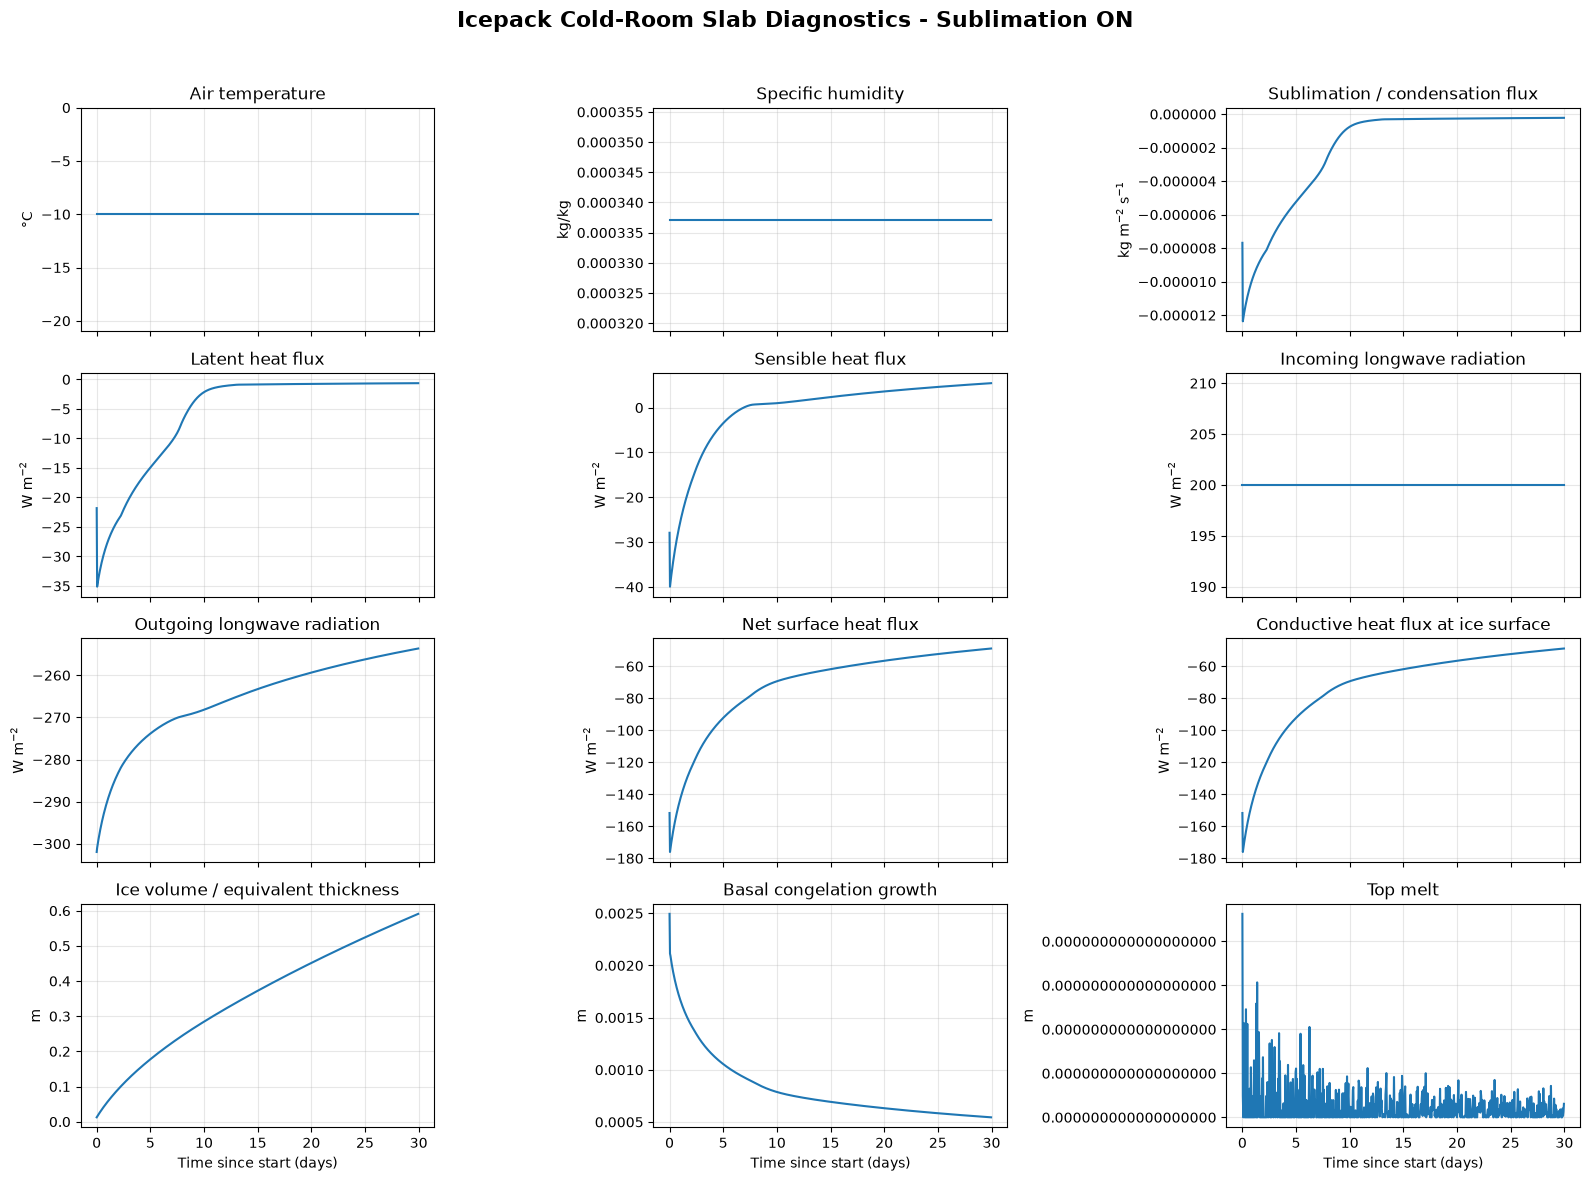

In [1]:

import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
import re


# ------------------------------------------------------------
# Find newest Icepack history file automatically
# ------------------------------------------------------------

files = glob.glob(
    "/home/bpng0/icepack-dirs/runs/icepack_test/history/icepack.h.*.nc"
)

if not files:
    raise FileNotFoundError("No Icepack history files found.")

file = max(files, key=os.path.getmtime)

print("Reading:", file)

ds = xr.open_dataset(file)


# ------------------------------------------------------------
# Read sublimation ON/OFF setting from icepack_in
# ------------------------------------------------------------

icepack_in = "/home/bpng0/cice-dirs/cases/icepack_test/icepack_in"

with open(icepack_in, "r") as f:
    nml_text = f.read()

match = re.search(
    r"sublimation_on\s*=\s*\.(true|false)\.",
    nml_text,
    re.IGNORECASE
)

if match:
    sublimation_on = match.group(1).lower() == "true"
else:
    sublimation_on = None

if sublimation_on is True:
    sublimation_status = "ON"
elif sublimation_on is False:
    sublimation_status = "OFF"
else:
    sublimation_status = "UNKNOWN"

print("Sublimation:", sublimation_status)


# ------------------------------------------------------------
# Select slab column
# ------------------------------------------------------------

slab_index = 1

hours = np.arange(ds.sizes["time"])
days = hours / 24.0


# ------------------------------------------------------------
# Variables to plot
# ------------------------------------------------------------

variables = {
    "Tair": (
        "Air temperature",
        "°C"
    ),

    "Qa": (
        "Specific humidity",
        "kg/kg"
    ),

    "evap": (
        "Sublimation / condensation flux",
        "kg m$^{-2}$ s$^{-1}$"
    ),

    "flat": (
        "Latent heat flux",
        "W m$^{-2}$"
    ),

    "fsens": (
        "Sensible heat flux",
        "W m$^{-2}$"
    ),

    "flw": (
        "Incoming longwave radiation",
        "W m$^{-2}$"
    ),

    "flwout": (
        "Outgoing longwave radiation",
        "W m$^{-2}$"
    ),

    "fsurf": (
        "Net surface heat flux",
        "W m$^{-2}$"
    ),

    "fcondtop": (
        "Conductive heat flux at ice surface",
        "W m$^{-2}$"
    ),

    "vice": (
        "Ice volume / equivalent thickness",
        "m"
    ),

    "congel": (
        "Basal congelation growth",
        "m"
    ),

    "meltt": (
        "Top melt",
        "m"
    ),
}


# ------------------------------------------------------------
# Create dashboard
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    3,
    figsize=(16, 12),
    sharex=True
)

fig.suptitle(
    f"Icepack Cold-Room Slab Diagnostics - Sublimation {sublimation_status}",
    fontsize=16,
    fontweight="bold"
)

axes = axes.flatten()


# ------------------------------------------------------------
# Plot each variable
# ------------------------------------------------------------

for ax, (var, (name, units)) in zip(axes, variables.items()):

    y = ds[var].isel(ni=slab_index).values

    # Convert air temperature from Kelvin to Celsius
    if var == "Tair":
        y = y - 273.15
        ax.set_ylim(-21, 0)

    ax.plot(days, y)

    ax.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False
    )

    ax.set_title(name)
    ax.set_ylabel(units)
    ax.grid(True, alpha=0.3)


# ------------------------------------------------------------
# X-axis labels
# ------------------------------------------------------------

for ax in axes[-3:]:
    ax.set_xlabel("Time since start (days)")


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

Reading: /home/bpng0/icepack-dirs/runs/icepack_test/history/icepack.h.20250101.nc
Sublimation: ON


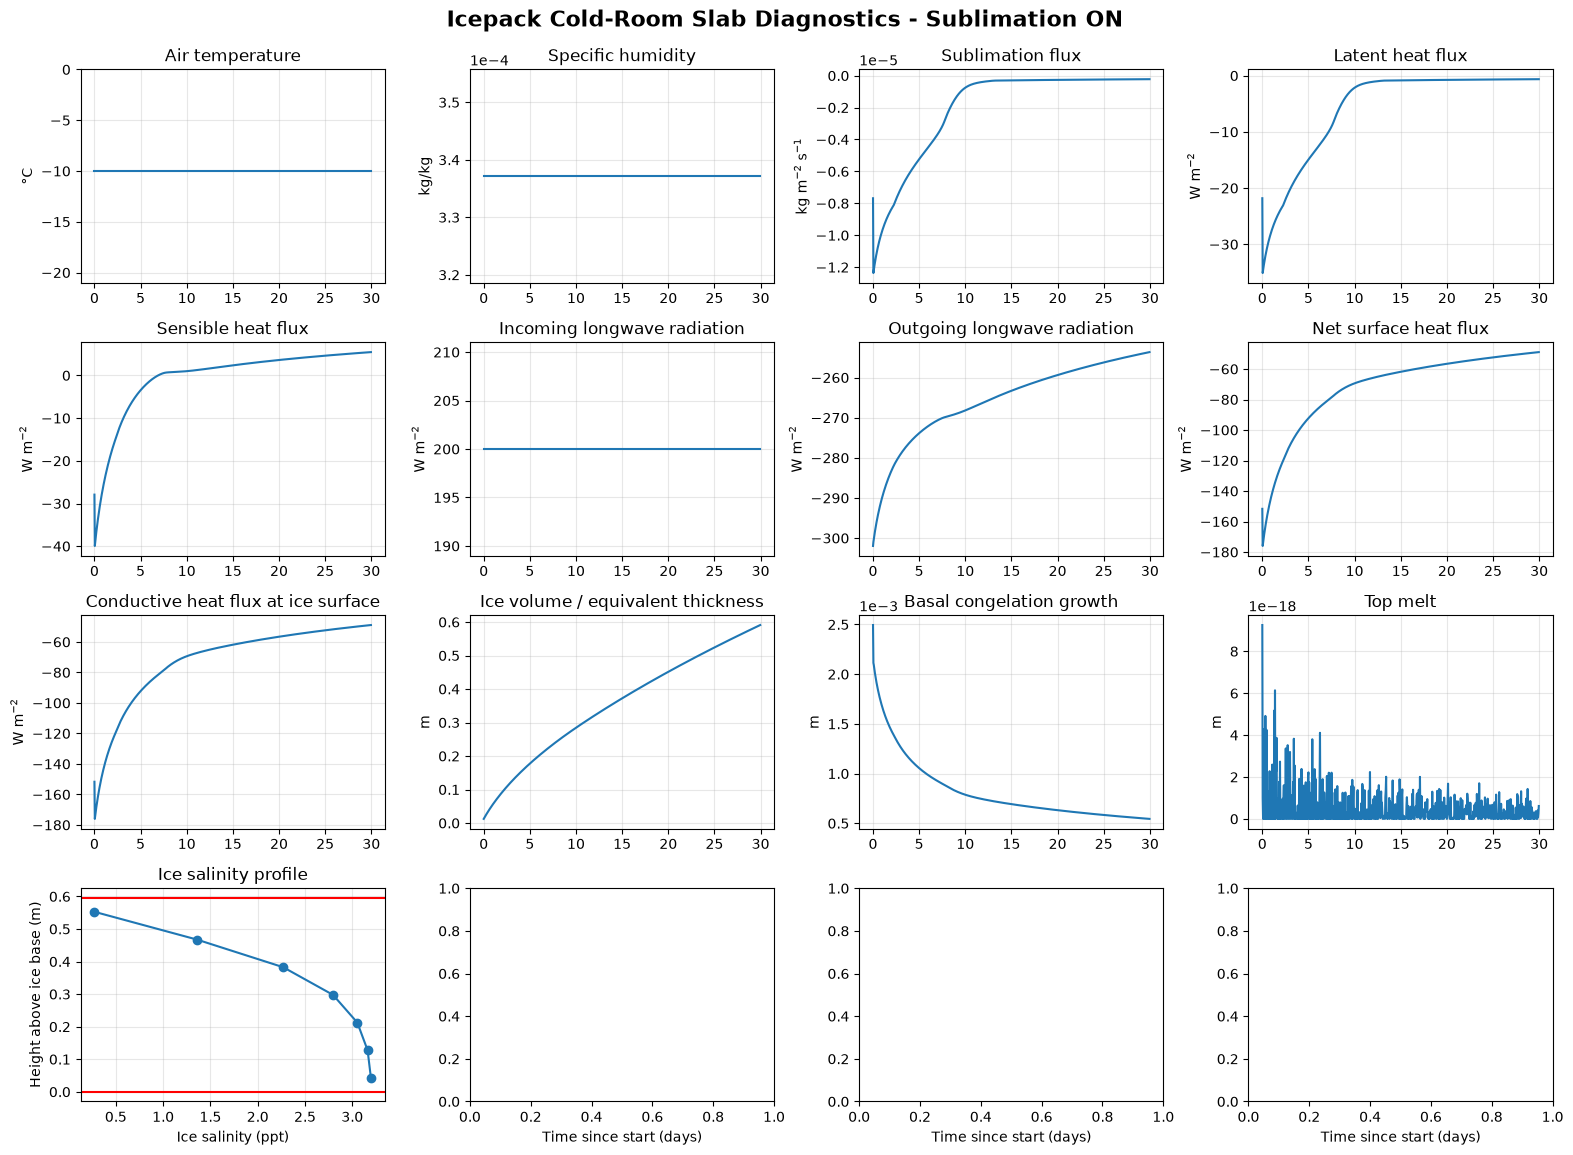

In [2]:

import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
import re


# ------------------------------------------------------------
# Find newest Icepack history file automatically
# ------------------------------------------------------------

files = glob.glob(
    "/home/bpng0/icepack-dirs/runs/icepack_test/history/icepack.h.*.nc"
    
    
)

if not files:
    raise FileNotFoundError("No Icepack history files found.")

file = max(files, key=os.path.getmtime)

print("Reading:", file)

ds = xr.open_dataset(file)


# ------------------------------------------------------------
# Read sublimation ON/OFF setting from icepack_in
# ------------------------------------------------------------

icepack_in = "/home/bpng0/cice-dirs/cases/icepack_test/icepack_in"

with open(icepack_in, "r") as f:
    nml_text = f.read()

match = re.search(
    r"sublimation_on\s*=\s*\.(true|false)\.",
    nml_text,
    re.IGNORECASE
)

if match:
    sublimation_on = match.group(1).lower() == "true"
else:
    sublimation_on = None

if sublimation_on is True:
    sublimation_status = "ON"
elif sublimation_on is False:
    sublimation_status = "OFF"
else:
    sublimation_status = "UNKNOWN"

print("Sublimation:", sublimation_status)


# ------------------------------------------------------------
# Select slab column
# ------------------------------------------------------------

slab_index = 1

hours = np.arange(ds.sizes["time"])
days = hours / 24.0


# ------------------------------------------------------------
# Variables to plot
# ------------------------------------------------------------

variables = {
    "Tair": (
        "Air temperature",
        "°C"
    ),

    "Qa": (
        "Specific humidity",
        "kg/kg"
    ),

    "evap": (
        "Sublimation flux",
        "kg m$^{-2}$ s$^{-1}$"
    ),

    "flat": (
        "Latent heat flux",
        "W m$^{-2}$"
    ),

    "fsens": (
        "Sensible heat flux",
        "W m$^{-2}$"
    ),

    "flw": (
        "Incoming longwave radiation",
        "W m$^{-2}$"
    ),

    "flwout": (
        "Outgoing longwave radiation",
        "W m$^{-2}$"
    ),

    "fsurf": (
        "Net surface heat flux",
        "W m$^{-2}$"
    ),

    "fcondtop": (
        "Conductive heat flux at ice surface",
        "W m$^{-2}$"
    ),

    "vice": (
        "Ice volume / equivalent thickness",
        "m"
    ),

    "congel": (
        "Basal congelation growth",
        "m"
    ),

    "meltt": (
        "Top melt",
        "m"
    ),
}


# ------------------------------------------------------------
# Create dashboard
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 12),
    sharex=False
)



fig.suptitle(
    f"Icepack Cold-Room Slab Diagnostics - Sublimation {sublimation_status}",
    fontsize=16,
    fontweight="bold"
)



fig.subplots_adjust(
    left=0.06,
    right=0.98,
    top=0.93,
    bottom=0.07,
    wspace=0.28,
    hspace=0.28
)

axes = axes.flatten()


# ------------------------------------------------------------
# Plot each variable
# ------------------------------------------------------------

for ax, (var, (name, units)) in zip(axes, variables.items()):


    

    y = ds[var].isel(ni=slab_index).values

    # Convert air temperature from Kelvin to Celsius
    if var == "Tair":
        y = y - 273.15
        ax.set_ylim(-21, 0)

    ax.plot(days, y)

    ax.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False
    )

    ax.set_title(name)
    ax.set_ylabel(units)
    ax.grid(True, alpha=0.3)

for ax in np.ravel(axes):
    ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 3))

# ------------------------------------------------------------
# X-axis labels
# ------------------------------------------------------------

for ax in axes[-3:]:
    ax.set_xlabel("Time since start (days)")


sal_profile = ds["trcrn"].isel(
    time=-1,
    ncat=0,
    ntrcr=slice(9, 16),
    ni=0
).values

hi = float(ds["vice"].isel(time=-1, ni=0).values)

z = (np.arange(7) + 0.5) / 7 * hi

sal_ax = axes[12]

sal_ax.plot(sal_profile[::-1], z, marker="o")
sal_ax.axhline(0, color="red", label="Ice base")
sal_ax.axhline(hi, color="red", label="Ice surface")

sal_ax.set_xlabel("Ice salinity (ppt)")
sal_ax.set_ylabel("Height above ice base (m)")
sal_ax.set_title("Ice salinity profile")
sal_ax.grid(True, alpha=0.3)








# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------